# This this the tutorial notebook to help you use FAMILY 

## Prerequisites

The tutorial is based on the benchmark dataset you can find in the github repo. More information on how this benchmark data are created can be find in the dedicated notebook. For each angular resolution, check that you have :

1. The catalog : in this tutorial this is a .csv table. You can use any table format you want as long as you can provide a function to read it and convert it into a pandas DataFrame.
2. The config file : in .toml format. It is used to interpret the columns of one table. For example, what labels are the X and Y coordinates, what are the conversion factors and indicate other header informations about the data you provide.
3. Optional : the .fits image from which your structures are extracted from, or whatever background image is associated to your dataset.
4. Optional : A region of your background image that represent the field of view in which the structures of your catalog are extracted.

# Open the data

## Locate where your tables are

In [1]:
from pathlib import Path
path = Path("./benchmark/config/").resolve()

## Define a reading function

The function needs to return a pandas DataFrame

In [2]:
import pandas as pd
reader = lambda x: pd.read_csv(x, delimiter=",", comment="#")

## After you configured all the config files

You need to instantiate Data class objects and put them into a DataSet class object.
Each table is associated to one Data object. Their association constitutes the DataSet object. This object is just an aggregator of Data.

In [3]:
from analysis import analyse

dataset = analyse.DataSet(
    analyse.Data(config, reader_to_df=reader)
    for config in path.glob("*.toml")
)

### Attributes of Data class

- 'path': path of the config file that is used to read the data
- 'df': normalised dataframe the code reads
- 'comment': any comment in the config file
- 'catalog': origin of catalog file
- 'fits_img': fits image from which the objects are extracted
- 'beam': observation beam (in arcsec)
- 'wavelength': wavelenght of observation (in µm)
- 'distance': distance of the region (in pc)
- 'fov_window': polygon object that define the field of view of extraction (-1 if all image is used)
- 'color': color used to represent the data in the figures

### Check up

After aggregating all your catalogs you can have a look at the number of elements :

In [4]:
for name, data in dataset.items():
    print(f"sample {name} : {len(data.df)} elements")
    
print(f"total #elements = {sum(data.df.shape[0] for data in dataset)}")

sample L01 : 12 elements
sample L02 : 12 elements
sample L03 : 14 elements
sample L04 : 17 elements
sample L05 : 19 elements
total #elements = 74


# Reconstruct the parentality (i.e. the network)

In [5]:
network = analyse.Network(dataset, min_overlap=0.75)

## Check on the network

By printing the network you can look at its main properties :
- Minimum overlap between parent and children used to build the parentality
- Number of nodes (i.e. objects)
- Number of edges (i.e. spatial overlap between each object)
- Number of component (i.e. number of disconnected sub-graph). *We come back to this at [Section : Extract the structures.](#Extract-the-structures)*
- Levels used to build the network

**Note that there are 10 disconnected components in this network.**

In [6]:
print(network)

Network
min_overlap - 0.75
n_nodes - 74
n_edges - 77
n_components - 10
levels - (0.0625, 0.125, 0.25, 0.5, 1.0)


## DataFrame view

You can have a DataFrame view of the network with its main characteristics. Note that we have a total of 74 line, which corresponds to the total number of objects in our benchmark dataset.

In [7]:
from analysis import network_utility as utility
clumps = utility.toDataFrame(network.network)
clumps

,_level,_R,_Polygon,_A,_B,_X,_Holes,_Theta,_Y,_beam,_Kind,_Fractality
0,0,1163.564086,POLYGON ((-2.08658849193883 -8.882758692888459...,0.349059,0.299280,-1.750423,0,2.868955,-8.976751,0.0625,NodeKind.SINK,None
1,0,1221.246594,"POLYGON ((6.355116666275062 5.509765275487186,...",0.381910,0.301329,6.363394,0,1.592471,5.127945,0.0625,NodeKind.SINK,None
2,0,960.827143,POLYGON ((4.262331323921199 -1.262994358897292...,0.311934,0.228361,4.049875,0,-0.821542,-1.034597,0.0625,NodeKind.SINK,None
3,0,1258.925572,"POLYGON ((6.80884635052061 -4.831351514976019,...",0.386918,0.316065,6.945946,0,1.933002,-5.193165,0.0625,NodeKind.SINK,None
4,0,970.398743,POLYGON ((5.574950514363674 -6.542288728543264...,0.305581,0.237777,5.807902,0,2.437695,-6.740059,0.0625,NodeKind.SINK,None
...,...,...,...,...,...,...,...,...,...,...,...,...
69,4,5333.362611,"POLYGON ((2.660148844341113 3.73095646984706, ...",1.632452,1.344487,2.127991,0,1.238741,2.187678,1.0000,NodeKind.SOURCE,[1.0]
70,4,4272.556094,POLYGON ((-7.221788351547324 -1.61500755918036...,1.374163,1.025020,-7.982926,0,0.983765,-2.759121,1.0000,NodeKind.SOURCE,[1.0912806233094392]
71,4,4163.435099,POLYGON ((-8.985246860790676 -0.86816928453392...,1.343551,0.995508,-7.973582,0,2.423373,-1.752286,1.0000,NodeKind.SOURCE,[1.1689595163588151]
72,4,6413.461040,POLYGON ((2.3053929718240775 -4.07752226391344...,2.007738,1.580785,0.949390,0,-0.829305,-2.596891,1.0000,NodeKind.SOURCE,[1.0]


# Extract the structures

In our network we have 10 disconnected components. Which means that there is 10 sub-network whose elements don't spatially overlap. This is the number of independant multi-scale structure. We can extract these multi-scale structures and compute their fractality individually.

In [8]:
network.extractStructures()

## Check up on these structures

The attribute network.structures now contains a list of Structure objects. Each Structure object contains information about the structure, such as :
- component : The label of the nodes it is composed of
- sinks : the number of sinks (nodes without child)
- sources : the number of sources (nodes without parents)
- mode : hierarchical, linear or isolated
- fractality : related to the fragmentation spatial rate
- missed : number of holes in the network
- percmissed : number of missed in % of the total number of nodes
- maxR : biggest resolution available in this structure
- YSO : number of YSO
- gas : number of gas structures (cores/ellipsoids)

If you want to have a propoer table view of these structures, you can do this :

In [9]:
structure_table = network.getStructuresTable()
structure_table

,component,sinks,sources,mode,fractality,missed,percmissed,maxR,YSO,gas,polygon,size,xposition,yposition
0,"(0, 36, 50, 19, 62)",1,1,LINEAR,1.000000,0,0.00,1.0,0,3,POLYGON ((-1.3079204472403945 -7.5488219313371...,2.493013,-1.392199,-9.066496
1,"(1, 37, 51, 20, 63)",1,1,LINEAR,1.000000,0,0.00,1.0,0,3,"POLYGON ((5.182937500979292 6.70347648086091, ...",2.824382,5.903552,5.190801
2,"(64, 2, 38, 52, 21)",1,1,LINEAR,1.000000,0,0.00,1.0,0,3,POLYGON ((3.6235491613387887 0.136167070051093...,2.618336,4.353962,-1.190942
3,"(65, 3, 39, 53, 22)",1,1,LINEAR,1.000000,0,0.00,1.0,0,3,POLYGON ((8.005969049058784 -6.375065207960578...,2.598091,7.061455,-4.891410
4,"(66, 4, 40, 54, 23)",1,1,LINEAR,1.000000,0,0.00,1.0,0,3,"POLYGON ((6.42163429816917 -7.915677995894772,...",2.442545,5.630147,-6.706865
5,"(67, 68, 5, 6, 7, 8, 41, 10, 42, 43, 9, 56, 55...",6,2,HIERARCHICAL,1.479549,7,0.28,1.0,0,10,POLYGON ((8.253847743696411 -3.706019147797537...,3.252109,9.280162,-2.411275
6,"(69, 11, 44, 57, 29)",1,1,LINEAR,1.000000,0,0.00,1.0,0,3,"POLYGON ((2.72235554873071 3.707393300589287, ...",2.625336,2.127991,2.187678
7,"(32, 70, 71, 12, 45, 14, 13, 46, 58, 59, 30, 31)",3,2,HIERARCHICAL,1.130120,3,0.20,1.0,0,7,POLYGON ((-7.128593516256042 -3.35328924355578...,2.581457,-8.047485,-2.307263
8,"(33, 72, 15, 47, 60)",1,1,LINEAR,1.000000,0,0.00,1.0,0,3,POLYGON ((2.2460821431277105 -4.12850955118860...,3.157013,0.949390,-2.596891
9,"(34, 35, 73, 16, 17, 18, 48, 49, 61)",3,1,HIERARCHICAL,1.297526,0,0.00,1.0,0,5,POLYGON ((-7.143998107590339 10.75716161048234...,2.102721,-7.407338,9.367358


## View the structures 

### Using the interactive applet

You may want to inspect all the structures or the network. In this tkinter window you can look at the structures in their physical form and compare them to the equivalent network. You can change the background and add some colors too!

### Using static plots

Here are more regular graphics. You select the background and plot a specific structure.

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


INFO: Auto-setting vmin to  5.843e-34 [aplpy.core]
INFO: Auto-setting vmax to  4.497e+01 [aplpy.core]


Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


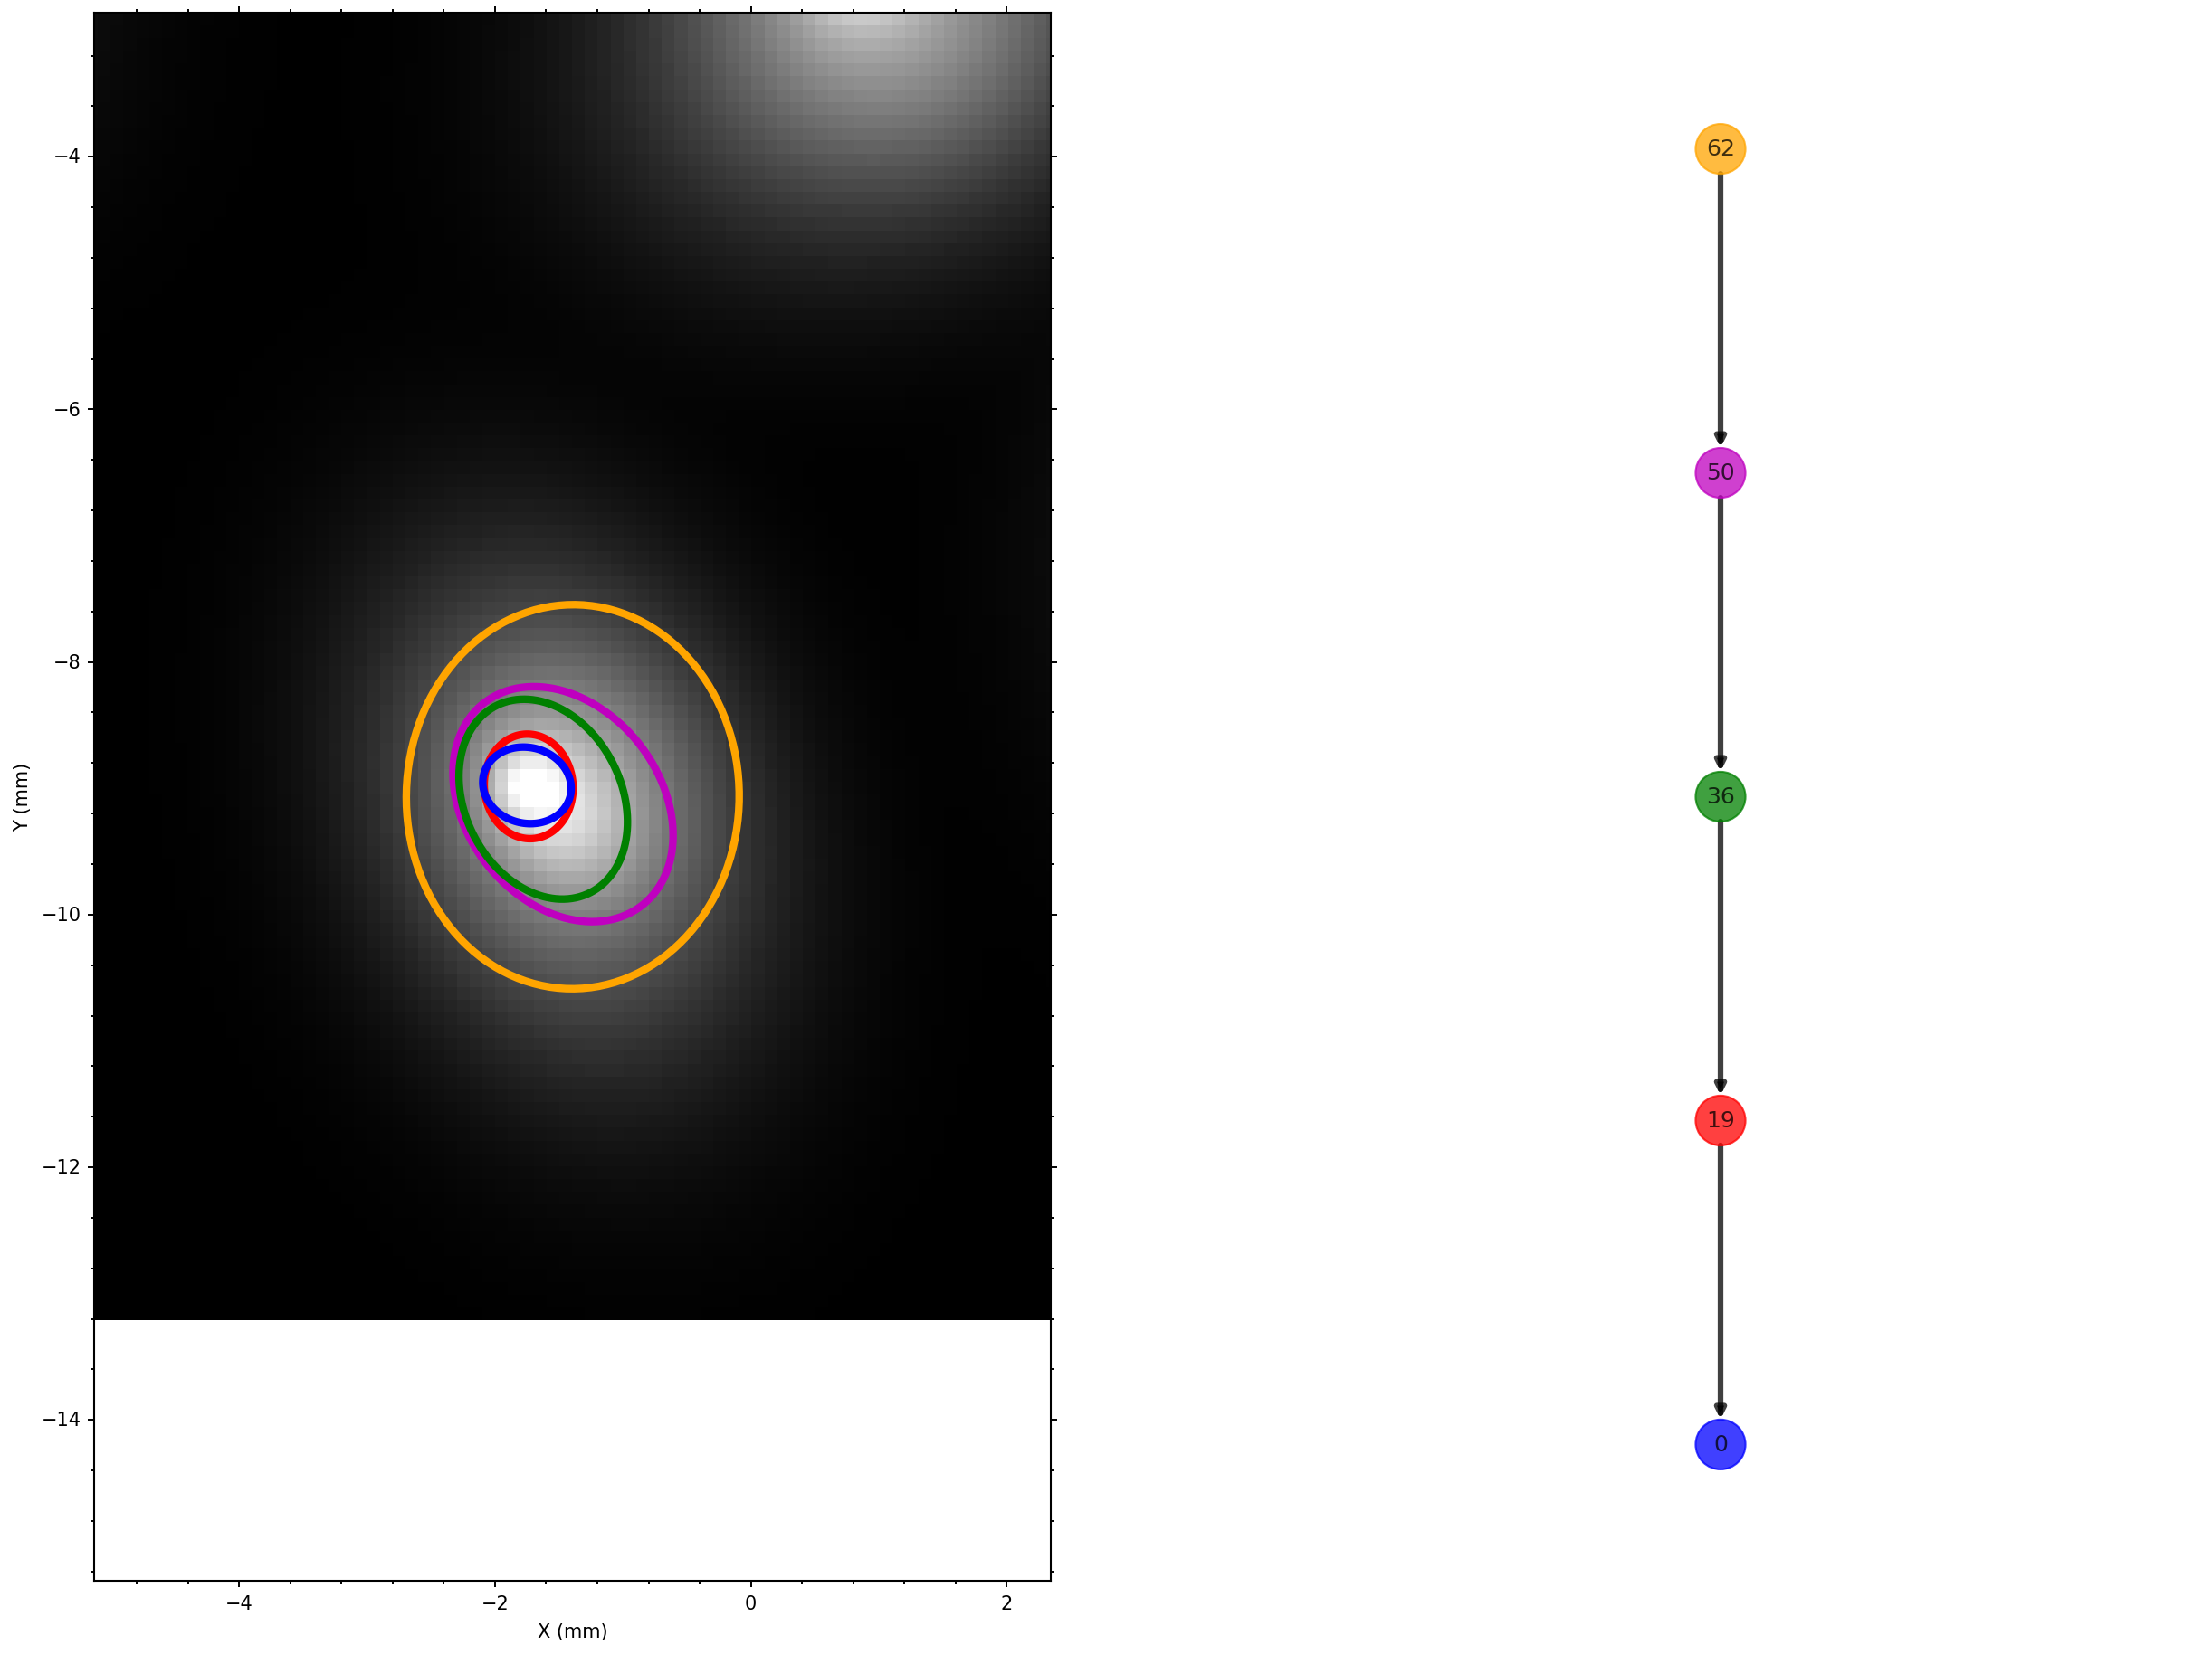

In [10]:
import matplotlib.pyplot as plt
%matplotlib inline

plt.rcParams['figure.dpi'] = 150 

image = dataset["L01"].fits_img
fig = network.structures[0].plot(image)
plt.show()

# Measurement of the fractality index

Below a small procedure to analyse the fractality index and its uncertainty. Then how to use it to estimate the 3D fragmentation spatial rate.

## Raw measurement

### Median and Mean

In [11]:
import numpy as np

fractalities = [struct.fractality for struct in network.structures]
print(f"Mean : {np.mean(fractalities)}\nMedian : {np.median(fractalities)}")

Mean : 1.090719491610979
Median : 1.0


If you want to take only the hierarchical structures (linears always give 1), be aware that struct.mode containe an Enum object that maps the name - value like this :

&emsp;**ISOLATED = 1**\
&emsp;**LINEAR = 2**\
&emsp;**HIERARCHICAL = 3**


So, you need to filter the structures like this :

In [12]:
fractalities = [struct.fractality for struct in network.structures if struct.mode.name == "HIERARCHICAL"]
print(f"Mean (Hierarchical only) : {np.mean(fractalities)}\nMedian (Hierarchical only) : {np.median(fractalities)}")

Mean (Hierarchical only) : 1.3023983053699293
Median (Hierarchical only) : 1.297525950003686


### Full distribution

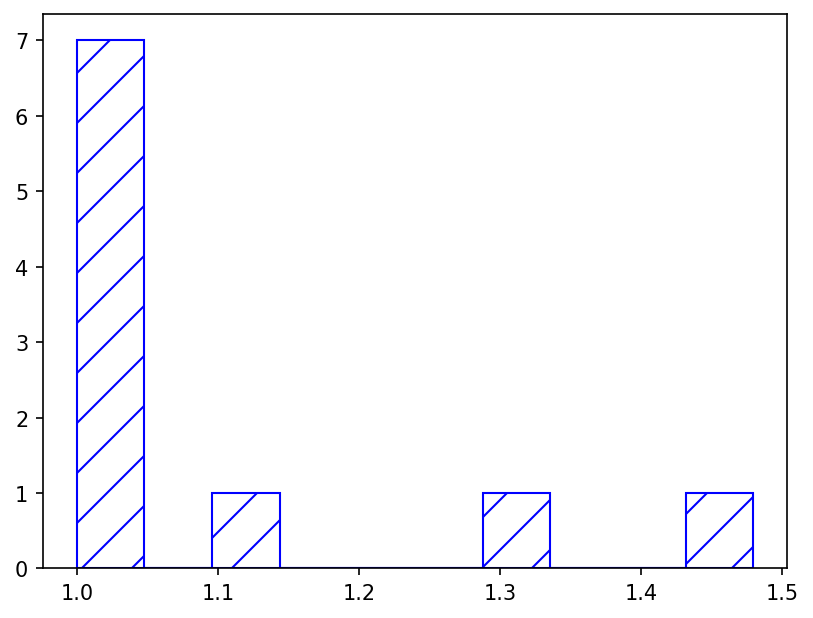

In [13]:
fractalities = [struct.fractality for struct in network.structures]

_ = plt.hist(fractalities, bins=10, edgecolor="b", histtype='stepfilled', fill=False, hatch='/')

### Productivity of fragments

For one structure, the productivity gives the ratio between the number of fragments at level $l$ and the number of sources in the structure. For all the structures, this shows the average productivity.

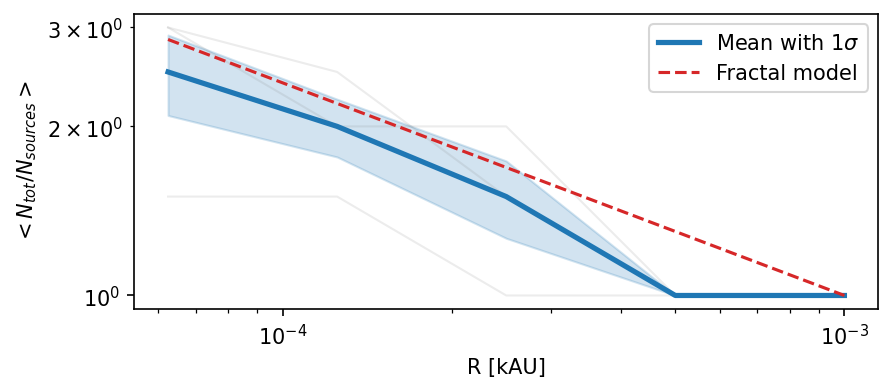

In [63]:
from analysis import plotter

distance = network.data["L01"].distance
x, meany, stdy, y = plotter.getFragCurve(network, distance, mode = "HIERARCHICAL")

fig, ax = plt.subplots()
x_kau = x / 1000

# individual structures
for serie in y:
    ax.plot(x_kau, serie, color="gray", alpha=0.15, linewidth=1)

ax.fill_between(
    x_kau, meany - stdy, meany + stdy,
    color="tab:blue", alpha=0.2
)
ax.plot(x_kau, meany, color="tab:blue", linewidth=2.5, label="Mean with 1$\\sigma$")

# If fragmentation is fractal, productivity should follow this law
fractality = 1.30
exponent = -(np.log(fractality)/np.log(2))
y_fractal = (x / max(x))**exponent
ax.plot(x_kau, y_fractal, "--", color="tab:red", label="Fractal model")

ax.set_xscale("log")
ax.set_yscale("log")

ax.set_xlabel("R [kAU]")
ax.set_ylabel("$<N_{tot}/N_{sources}>$")
ax.set_aspect("equal", adjustable="box")
ax.legend()

## 2D fragmentation spatial rate

### How to derive it ?

In two dimensions, the fragmentation spatial rate $\phi_{2D}$ is, by definition, related with the fractality metric using the following :

$$
\overline{\phi_{2D}} = \frac{\ln \mathcal{F}}{\ln 2}
$$

Where log is the natural logarithme (base $e$). Since $\mathcal{F}$ is averaged over the full spatial range, the corresponding fragmentation rate is also averaged over this range, as indicated by the bar notation. The associated uncertainty is given by:

$$
\Delta \overline{\phi_{2D}} = \frac{\Delta \mathcal{F}}{\mathcal{F} \ln 2}
$$

### Uncertainties

Because we are dealing with small samples of cores, the procedure is to apply these formulae on the median fractality taken from the whole sample of structures.  This approach therefore **assumes that all structures undergo the same fragmentation process**. The fractality you obtained is measured without accounting for the missing nodes inside the network. These missing nodes may result from:

- Limitations of the core extraction tool
- The absence or non-detection of an object at the resolution or wavelength used
- Noisy data
- Other possible causes

As a consequence, we treat the median fractality as a lower bound on the actual fractality of the population (valid as long as our previous assumption holds). The upper bound is obtained by computing the fractality after filling all holes in the graph. You can construct a graph with these new virtual nodes :

In [ ]:
from analysis import network_utility as utility

virtual = utility.virtualNodes(network.network, network.levels)

Then recompute the fractalities, extract the structures and see what changed

In [ ]:
network_filled = analyse.Network(*network.data, min_overlap=network.min_overlap, graph=virtual)
utility.fractality(network_filled.network)

network_filled.extractStructures()

fractalities = [struct.fractality for struct in network.structures if struct.mode.name == "HIERARCHICAL"]
fractalities_filled = [struct.fractality for struct in network_filled.structures if struct.mode.name == "HIERARCHICAL"]

print("median with virtual nodes", np.median(fractalities))
print("median without virtual nodes", np.median(fractalities_filled))

In [ ]:
_ = plt.hist(fractalities, bins=10, edgecolor="b", histtype='stepfilled', fill=False, hatch='/')
_ = plt.hist(fractalities_filled, bins=10, edgecolor="r", histtype='stepfilled', fill=False, hatch='/')

You have now an estimation for the lower (median with holes) $\mathcal{F}_{low}$ and upper bound (median without holes) $\mathcal{F}_{up}$ . You may want to select the fractality as :

$$
\mathcal{F} = \frac{\mathcal{F}_{up} + \mathcal{F}_{low}}{2}
$$

$$
\Delta \mathcal{F} = \frac{\mathcal{F}_{up} - \mathcal{F}_{low}}{2}
$$

In [ ]:
import fragmeasurement as fm

f_up = np.median(fractalities_filled)
f_low = np.median(fractalities)

fractality, delta_fractality = fm.estimated_f(f_up, f_low)
phi2D = fm.phi2D(fractality)
delta_phi2D = fm.delta_phi2D(fractality, delta_fractality)

print(f"Fragmentation rate in 2D : {phi2D}+/-{delta_phi2D}")

## What if structures undergo different fragmentation processes?

You can divide your sample into subsamples of cores with similar environments, locations, masses, or other relevant properties to group structures likely to share similar fragmentation behaviour. FAMILY can then be applied to each subsample separately.

A more general approach would be to measure $\phi_{\mathrm{2D}}$ for each structure individually, rather than assuming that all structures share the same fragmentation properties. This approach is not currently implemented.

## 3D fragmentation rate

### Projection + statistical uncertainties

The fragmentation rate you measured is a two dimensional metric. You can use the Julia notebook located in /model/geometrical_jl/synthetic.ipynb to generate a population of ellipsoid in 3D, project them in 2D and evaluate the relative difference $\psi$ between the fragmentation rates, define as :

$$
\psi = \frac{\overline{\phi_{2D}} - \overline{\phi_{3D}}}{\overline{\phi_{3D}}}
$$

You can then invert the equation to estimate the 3D fragmentation rate corresponding to a measured 2D fragmentation rate:

$$
\overline{\phi_{3D}} = \frac{\overline{\phi_{2D}}}{1 + \psi}
$$

The associated uncertainty is given below, where $\Delta\psi$ is the statistical uncertainty in the relative difference $\psi$. If $\psi$ is estimated from a plot/chart, you might want to consider the uncertainty due to the graphical reading when estimating $\Delta\psi$ :

$$
\Delta \overline{\phi_{3D}}
=
\sqrt{
    \left(\frac{\Delta \overline{\phi_{2D}}}{1+\psi}\right)^2
    +
    \left(
        \frac{\overline{\phi_{2D}}}
        {(1+\psi)^2} \Delta \psi
    \right)^2
}
$$

Below an example of the kind of plot you may use :
**the reference tables are currently being recomputed**


In [ ]:
import fragmeasurement as fm

# what you measured
# phi2d, delta_phi2d

# what you can read on the plot, obtained using the julia notebook
relative_error = 
delta_relative_error = 

phi3D = fm.phi3D(phi2d, relative_error=)
delta_phi2D = fm.delta_phi3D(phi2d, delta_phi2d, relative_error, delta_relative_error)

print(f"Fragmentation rate in 3D : {phi3D}+/-{delta_phi3D}")

# Compare your value with a theoretical model

The directory "model" contains the scripts "semianalytical.py" and "figures.py" that compute and display the 3D fragmentation rate computed using the model from Thomasson et al. 2024. This model gives you the instanteneous fragmentation rate. You previously measured the fragmentation rate averaged over a range of spatial scales. To compare this measurement with the model, you need to average the model prediction over the same range, using the same logarithmic weighting :

$$
\overline{\phi_{\mathrm{3D}}}
= \frac{1}{\ln(R_L/R_0)}
\int_{R_0}^{R_L} \phi_{\mathrm{3D}}(R)~\mathrm{dlnR}
$$

Depending on how the mass transfer rate $\xi$ is modelled, a degeneracy may occur regarding the value of $\overline{\phi_{\mathrm{3D}}}$. For example, in Thomasson et al. (2024), we assumed that $\xi$ was constant, but different choices of this constant yielded different values of $\overline{\phi_{\mathrm{3D}}}$. Measurements of $\phi_{\mathrm{3D}}$ therefore helped constrain $\xi$ in the context of the model.

More generally, comparing a model prediction for $\phi$ with a direct measurement can serve two purposes:

    1. Constrain a model parameter: use the measurement to determine which parameter values are compatible with the observations.

    2. Challenge a model prediction: if the parameters (initial conditions, mass transfer rate, instability prescription, etc.) are known, you can use the measurement to assess whether the prediction is consistent with the observations.

Note: this is basically what physics is. Formulating a model and testing it against observations that could falsify it. I have provided a framework and illustrated it with one model, now you can use this framework to test any model of your choice.